# ground_v1:在 predictor 里加 grounding 监督

**问题**:只有答案损失时,predictor 不需要找到题目说的物体。hardneg_v1 的任何一层都读不出物体位置(1.8–2.1 m,总答平均位置是 2.1 m),真场景和换场景的分数相同。

**做法**:hardneg_v1 不变,加一项监督。predictor 第 4 层(共 8 层)之后,取题目里物体名那几个 token 的隐状态求平均,接一个头,要求它 (a) 在本场景所有物体的中心里选出这个物体(交叉熵),(b) 回归出中心坐标(smooth L1)。输入里不加任何提示(没有 dino.txt,没有物体 token)。

**这份报告的三部分**:1 位置真值是怎么补出来的;2 方法和训练曲线;3 结果(VSI-Bench、留出集、定位本身)。

## 总结

- **真值数据补上了,而且质量可查**:训练集有真值的名字从 325,634 个增加到 714,592 个,至少一个名字有真值的行从 27.7% 到 57.4%;ScanNet++ 从 0 到 183,361 行。在 ScanNet 上用 EmbodiedScan 的框对照,重建的中心离框中心中位数 1.2 cm。
- **定位没有学会**:留出集上位置误差中位数 1.77 m(换场景 2.46 m,总答平均位置 2.06 m),在场景物体里选对的比例 7.5%(随机 2.9%)。事先定的线是明显低于 0.95 m,没有达到。
- **学到的是"这个场景的东西大概在哪",不是"这个名字指的物体在哪"**:把名字换成 object A / B 之后,误差还是 1.79 m。回归出的坐标和真值的相关系数约 0.6(换场景后约 0),说明它读了场景,但读到的内容几乎与名字无关。
- **主要是没学会,不是过拟合**:训练集上选对比例也只有 11–13%(留出集 7.5%),误差约 1.7 m(留出集 1.77 m)。这和之前在 958 个场景上过拟合的类别探针(训练 0.08 m,验证 0.95 m)情况相反。
- **训练结束时定位还在变好**:选对比例从 3% 缓慢升到 11%,最后三分之一升得最快。一个 epoch 没有训完这件事。
- **VSI-Bench 没有变好**:test(带位姿的 1,845 道选择题)选择题 4 任务平均 hardneg_v1 34.1,ground_v1 29.6;全部题的准确率 33.7 对 32.7。两个模型换场景后分数都不降,差别来自选项偏向(路线规划 33.3 → 16.7 只有 90 题,方向 hard 27.3 → 16.5、medium 29.6 → 39.9)。
- **留出集答题没有变化**:长答案 46.8(hardneg_v1 46.7),真场景减换场景 +3.4(+2.6);去词汇化后 33.0(31.8,随机 29.9),真场景和换场景相同。
- 没有评 MMSI-Bench。

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import io
from PIL import Image as PILImage
from IPython.display import Image, display
plt.rcParams["figure.dpi"] = 70

def picture(path):
    """A PNG shown as a JPEG, to keep the notebook small."""
    buffer = io.BytesIO()
    PILImage.open(path).convert("RGB").save(buffer, "JPEG", quality=78)
    display(Image(data=buffer.getvalue()))
load = lambda path: json.load(open(path))
S = load("../data/labels.stats.json")
G, H = load("../results/eval_final.json"), load("../../hardneg_v1/results/eval_final.json")
GD, HD = load("../results/eval_final_delex.json"), load("../../hardneg_v1/results/eval_final_delex.json")
RUNS, DELEX = {"hardneg_v1": H, "ground_v1": G}, {"hardneg_v1": HD, "ground_v1": GD}
MODES = ["real", "shuffled", "zero"]

def score(v):
    if v is None: return None
    return 100 * (v["acc"] if isinstance(v, dict) else v)

def by_mode(runs, ds, key):
    return pd.DataFrame({name: {m: score(r[m].get(ds, {}).get(key)) for m in MODES} for name, r in runs.items()}).T.astype(float).round(1)

def by_type(runs, ds, keep=lambda k: True):
    first = next(iter(runs.values()))
    rows = {}
    for k, v in first["real"][ds].items():
        if not keep(k): continue
        row = {"题数": v.get("rows") if isinstance(v, dict) else None,
               "随机": 100 * v["chance"] if isinstance(v, dict) and "chance" in v else None}
        for name, r in runs.items():
            real, shuf = score(r["real"][ds].get(k)), score(r["shuffled"][ds].get(k))
            row[f"{name} real"], row[f"{name} real-shuffled"] = real, None if real is None else real - shuf
        rows[k.replace("type/", "").replace("long/", "")] = row
    return pd.DataFrame(rows).T.dropna(axis=1, how="all").astype(float).round(1)

## 1 数据:题目里物体的位置真值

原数据集和 `experiments/slots_v2/data` 没有改动;新文件都在 `experiments/ground_v1/data/`(`jepa3d/tools/build_ground_labels.py`,作业 `jepa3d/trainbatch/ground_data.sbatch`)。

### 1.1 位置从哪来,准不准

每个场景先建一张物体表(中心坐标,场景自己的坐标系,米):

| 来源 | 场景 | 做法 |
|---|---|---|
| 框 | ScanNet | EmbodiedScan 的框中心 |
| 深度法 | ScanNet++(没有框) | SPAR 的 `depth_prediction_oc` 题给出同一张图里两个物体的中心像素,题目文字里写了中心深度("the shelf (red point) lies at 1.2 meters depth",答案 "2.3")。像素 + 深度 + 位姿 = 中心;相距 12 cm 以内的算同一个物体 |
| 射线求交 | 深度题没提到的物体 | SPAR 的 `spatial_imagination` 题给出该物体在若干帧里的中心像素,每个是一条过中心的射线;同名的射线都在 15 cm 内交于一点时取交点 |

动手前先在 ScanNet 上查了三件事(那里有框可以对照):SPAR 的点是不是 3D 中心的投影、坐标是什么单位、哪种颜色的点对应题目里的哪个 Object。结论:点是中心的投影,坐标是宽高的 0–1000;绿 = Object0,蓝 = Object1,红 = Object2,黄 = Object3。

场景物体表: 2007 个场景;物体数按来源 {'box': 34902, 'depth': 105031, 'rays': 3382}
ScanNet++ 每个场景的物体数: 中位数 131, 90 分位 219


,数量,中位数,90 分位,平均
SPAR 的点到最近框中心投影的距离(占图像尺寸的比例),506433.0,0.0005,0.0832,0.0284
深度法重建的中心到框中心(米),377131.0,0.0123,0.0354,0.0174
射线求交重建的中心到框中心(米),5604.0,0.0006,0.0033,0.0038


SPAR 的点落在某个框中心 2% 图像尺寸以内: 80.3%
有框可对照的提及 406468 个,其中不用框也能定位的 382735 个 (94.2%)


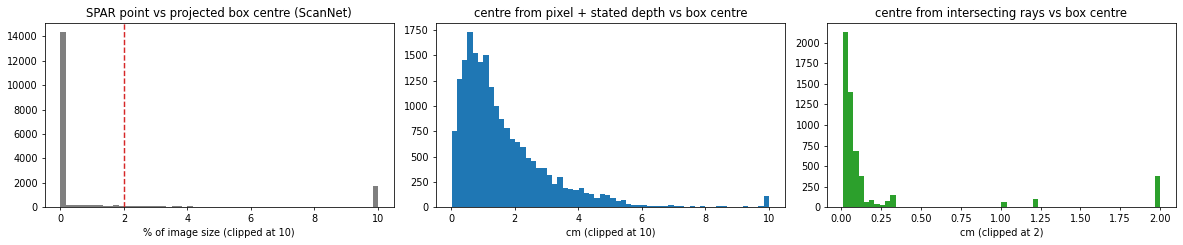

In [2]:
c = S["check_scannet"]
print("场景物体表:", S["scenes"], "个场景;物体数按来源", S["objects_by_source"])
print("ScanNet++ 每个场景的物体数: 中位数 %.0f, 90 分位 %.0f" % (S["scannetpp_objects_per_scene"]["median"], S["scannetpp_objects_per_scene"]["p90"]))
show = lambda d: {"数量": d["n"], "中位数": d["median"], "90 分位": d["p90"], "平均": d["mean"]}
check = pd.DataFrame({
    "SPAR 的点到最近框中心投影的距离(占图像尺寸的比例)": show(c["pixel_distance_to_nearest_box"]),
    "深度法重建的中心到框中心(米)": show(c["error_m_depth"]),
    "射线求交重建的中心到框中心(米)": show(c["error_m_rays"])}).T
display(check.round(4))
print("SPAR 的点落在某个框中心 2%% 图像尺寸以内: %.1f%%" % (100 * c["pixel_within_threshold"]))
print("有框可对照的提及 %d 个,其中不用框也能定位的 %d 个 (%.1f%%)" % (c["mentions_with_box"], c["found_without_boxes"], 100 * c["found_without_boxes"] / c["mentions_with_box"]))
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
ax[0].hist(np.clip(c["pixel_distance_to_nearest_box"]["sample"], 0, 0.1) * 100, bins=60, color="tab:gray")
ax[0].axvline(2, color="tab:red", ls="--"); ax[0].set_title("SPAR point vs projected box centre (ScanNet)"); ax[0].set_xlabel("% of image size (clipped at 10)")
ax[1].hist(np.clip(np.array(c["error_m_depth"]["sample"]) * 100, 0, 10), bins=60, color="tab:blue")
ax[1].set_title("centre from pixel + stated depth vs box centre"); ax[1].set_xlabel("cm (clipped at 10)")
ax[2].hist(np.clip(np.array(c["error_m_rays"]["sample"]) * 100, 0, 2), bins=60, color="tab:green")
ax[2].set_title("centre from intersecting rays vs box centre"); ax[2].set_xlabel("cm (clipped at 2)")
plt.tight_layout(); plt.show()

- **SPAR 的点就是 3D 中心的投影**:到最近框中心投影的距离中位数是图像尺寸的 0.05%;80.3% 在 2% 以内。其余约 20% 是 EmbodiedScan 没有框的物体。
- **深度法的误差约 1 cm**:中位数 1.2 cm,90 分位 3.5 cm(文字里的深度只保留一位小数,多次提及取平均后更准)。
- **射线求交几乎没有误差**,但只占少数(ScanNet++ 上 3,382 个物体,深度法 105,031 个)。
- 把 ScanNet 当作没有框的场景来做,94.2% 的提及仍能定位。所以这套做法可以搬到 ScanNet++。
- ScanNet++ 每个场景的物体表中位数 131 个。这个数偏大:12 cm 的合并半径下,同一个物体可能被拆成两个相邻的条目(训练时离目标 20 cm 以内的其他条目不算错误选项)。

### 1.2 哪个名字是哪个物体,覆盖了多少

| 途径 | 适用的行 | 做法 |
|---|---|---|
| 原始行的点 | SPAR `spatial_imagination_*_video_hard` | manifest 的 `src` 指回 SPAR 原始行,原始行里有每个 (ObjectK) 在某一帧的中心像素;中心投影落在这个像素上的物体就是它。同名的多个物体也能分开 |
| 名字唯一 | 其余的行(VSI-590K、appearance_order、obj_count) | 物体表里的物体由上面那些 SPAR 行(和 EmbodiedScan 类别)命名;场景里恰好一个物体叫这个名字时取它 |

真值只在中心能投影进这一行的某个视角时保留。

,行数,至少 1 个名字有真值(之前),至少 1 个名字有真值(现在),所有名字都有真值(现在),名字数,有真值的名字(之前),有真值的名字(现在),行覆盖 % (现在)
all,658518,182340,378078,61753,1743019,325634,714592,57.4
spar/appearance_order,69333,34498,56913,3100,276350,58341,108911,82.1
spar/obj_count,141668,291,892,825,144053,291,892,0.6
spar/room_size,35705,0,0,0,0,0,0,0.0
spar/spatial_imagination_oc_video_hard,127934,53831,115619,27518,383795,92189,221079,90.4
spar/spatial_imagination_oo_video_hard,65353,24080,62037,8741,261411,50776,150187,94.9
subset:scannet,309683,182340,194717,41080,799029,325634,399350,62.9
subset:scannetpp,348835,0,183361,20673,943990,0,315242,52.6
vsi590k/absolute_count,6083,36,84,84,6083,36,84,1.4
vsi590k/absolute_direction_object,19242,7375,14414,2157,57726,13585,24250,74.9


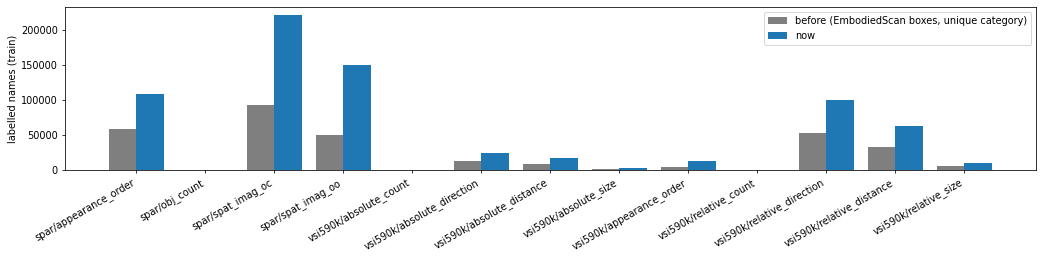

,all,subset:scannet,subset:scannetpp
原始行的点 → 框,182989,182989,0
名字唯一 → 框,216361,216361,0
原始行的点 → 深度法物体,162141,0,162141
名字唯一 → 深度法物体,119258,0,119258
原始行的点 → 射线求交物体,26136,0,26136
名字唯一 → 射线求交物体,7707,0,7707
没标上:中心不在这行的视角里,227957,120031,107926
没标上:场景里没有叫这个名字的物体,357294,85978,271316
没标上:有多个叫这个名字的物体,259910,136611,123299
没标上:原始行的点对不上任何物体,160743,56882,103861


In [3]:
# 补之前:只用 EmbodiedScan 的框、类别名相同且场景里只有一个(作业 13536 的计数)
BEFORE = {"all": (182340, 325634), "subset:scannet": (182340, 325634), "subset:scannetpp": (0, 0),
          "spar/appearance_order": (34498, 58341), "spar/obj_count": (291, 291), "spar/room_size": (0, 0),
          "spar/spatial_imagination_oc_video_hard": (53831, 92189), "spar/spatial_imagination_oo_video_hard": (24080, 50776),
          "vsi590k/absolute_count": (36, 36), "vsi590k/absolute_direction_object": (7375, 13585),
          "vsi590k/absolute_distance_object": (6522, 9062), "vsi590k/absolute_size_object": (2509, 2509),
          "vsi590k/absolute_size_room": (0, 0), "vsi590k/appearance_order": (2908, 4853), "vsi590k/relative_count": (4, 4),
          "vsi590k/relative_direction_object": (29194, 53694), "vsi590k/relative_distance_object": (15556, 33452),
          "vsi590k/relative_size_object": (5536, 6842)}
T = S["manifests"]["train_f8.jsonl"]
cov = pd.DataFrame({g: {"行数": v["rows"], "至少 1 个名字有真值(之前)": BEFORE[g][0], "至少 1 个名字有真值(现在)": v.get("rows_some_name_labelled", 0),
                        "所有名字都有真值(现在)": v.get("rows_all_names_labelled", 0),
                        "名字数": v.get("names", 0), "有真值的名字(之前)": BEFORE[g][1], "有真值的名字(现在)": v.get("names_labelled", 0)}
                    for g, v in T.items()}).T
cov["行覆盖 % (现在)"] = (100 * cov["至少 1 个名字有真值(现在)"] / cov["行数"]).round(1)
display(cov)
types = [g for g in T if "/" in g and T[g].get("names", 0) > 0]
fig, ax = plt.subplots(figsize=(15, 3.8))
x = np.arange(len(types))
ax.bar(x - 0.2, [BEFORE[g][1] for g in types], 0.4, label="before (EmbodiedScan boxes, unique category)", color="tab:gray")
ax.bar(x + 0.2, [T[g].get("names_labelled", 0) for g in types], 0.4, label="now", color="tab:blue")
ax.set_xticks(x); ax.set_xticklabels([g.replace("_object", "").replace("spatial_imagination", "spat_imag").replace("_video_hard", "") for g in types], rotation=30, ha="right")
ax.set_ylabel("labelled names (train)"); ax.legend(); plt.tight_layout(); plt.show()
how = {"labelled_row_box": "原始行的点 → 框", "labelled_name_box": "名字唯一 → 框", "labelled_row_depth": "原始行的点 → 深度法物体",
       "labelled_name_depth": "名字唯一 → 深度法物体", "labelled_row_rays": "原始行的点 → 射线求交物体", "labelled_name_rays": "名字唯一 → 射线求交物体",
       "names_out_of_view": "没标上:中心不在这行的视角里", "names_no_such_object": "没标上:场景里没有叫这个名字的物体",
       "names_several_objects": "没标上:有多个叫这个名字的物体", "names_row_pixel_without_object": "没标上:原始行的点对不上任何物体",
       "names_row_not_matched": "没标上:原始行的物体对不上题目里的名字", "names_scene_without_objects": "没标上:场景没有物体表"}
pd.DataFrame({g: {label: T[g].get(k, 0) for k, label in how.items()} for g in ("all", "subset:scannet", "subset:scannetpp")})

- 有真值的名字 325,634 → 714,592(占全部名字的 41.0%);至少一个名字有真值的行 182,340 → 378,078(57.4%);所有名字都有真值的行 24,005 → 61,753。
- ScanNet++ 从没有真值到 183,361 行、315,242 个名字。ScanNet 上也多了约 7.4 万个名字:原始行的点能分开同名物体,也不受类别叫法不同的影响。
- 计数题仍然几乎没有(问的就是多个同名物体);房间面积题没有物体。
- 没标上的主要原因:中心不在这一行的 8 个视角里(22.8 万);场景里没有叫这个名字的物体(35.7 万,其中 ScanNet++ 27.1 万:VSI-590K 提到的物体没有出现在用来命名的 SPAR 行里);有多个同名物体(26.0 万)。
- 留出集 6,786 行里 5,180 行、9,769 个名字有真值(之前 2,681 行、4,741 个)。

### 1.3 看图检查

圆圈是真值中心投影到这一行各个视角里的位置。

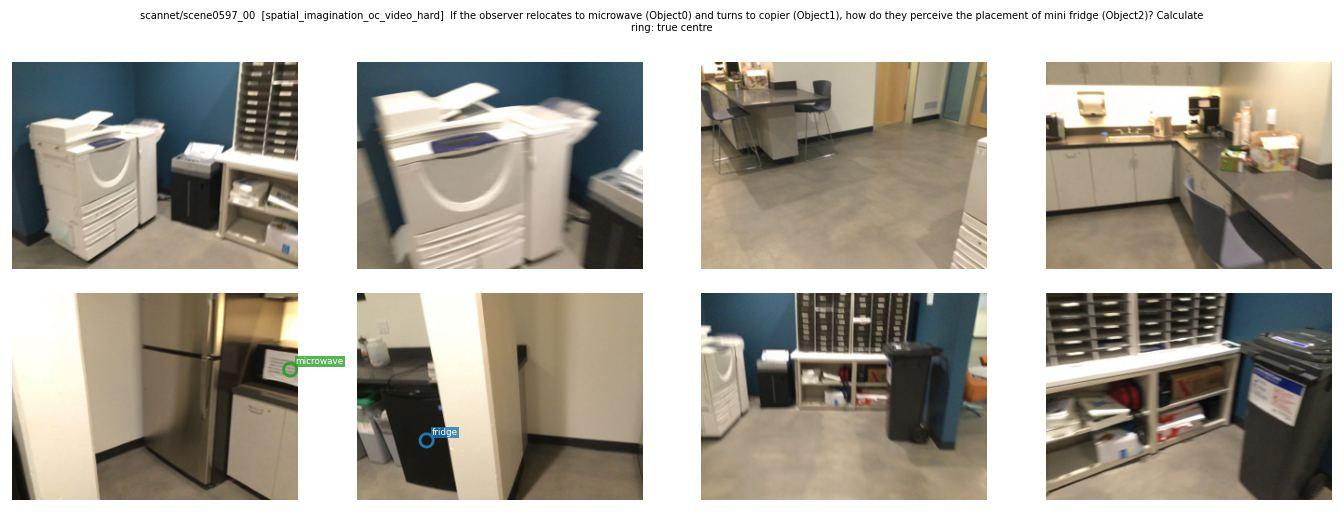

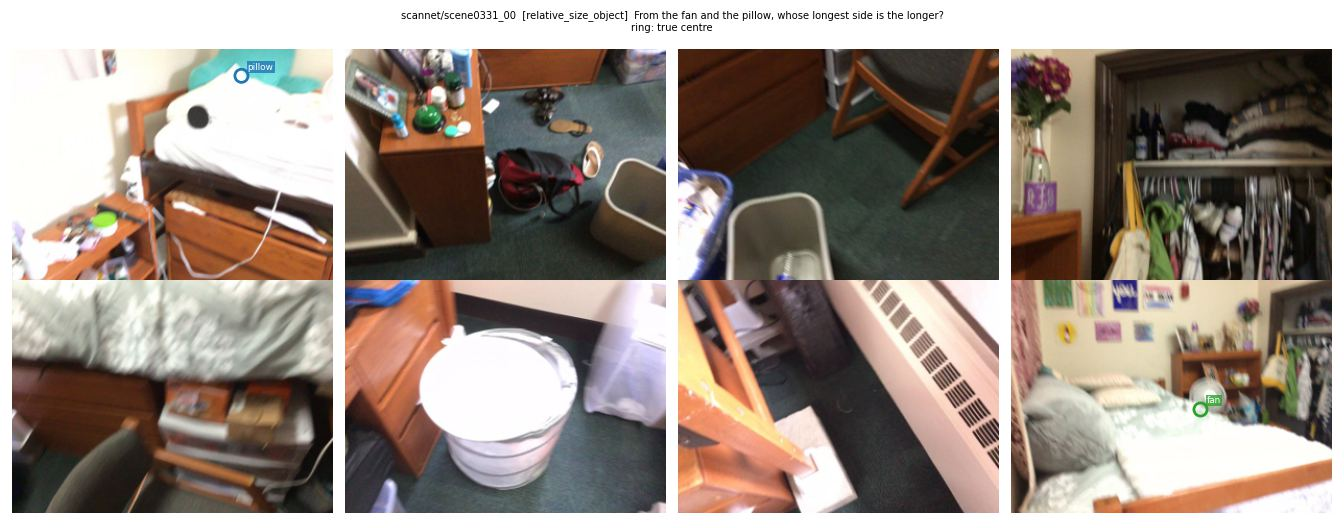

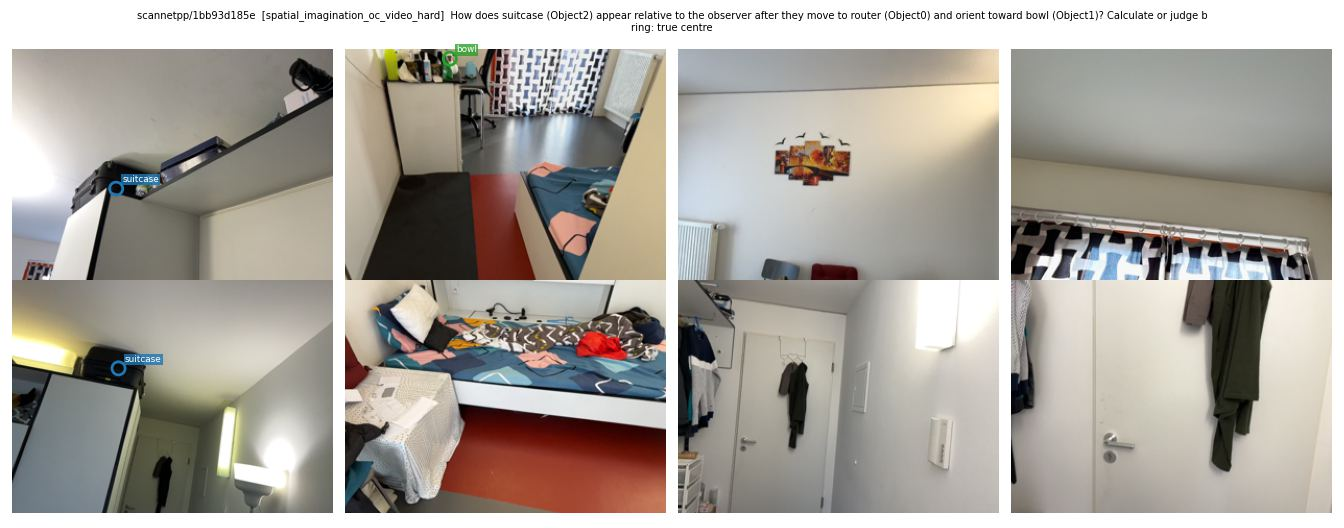

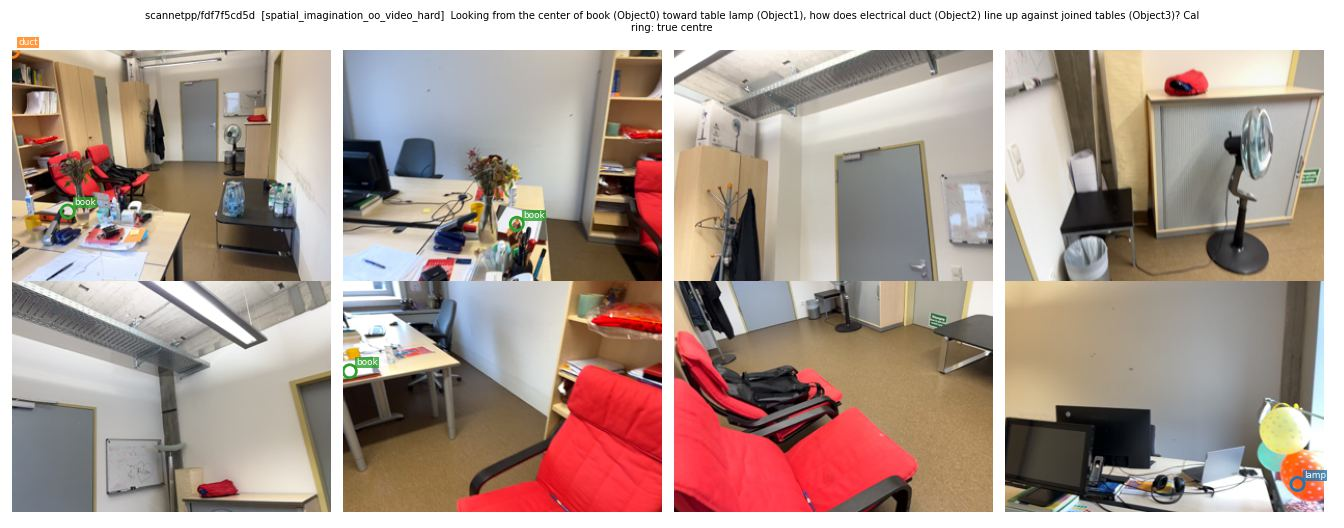

In [4]:
for name in ("labels_scannet_1", "labels_scannet_0", "labels_scannetpp_0", "labels_scannetpp_1"):
    picture(f"../results/figs/{name}.png")

### 1.4 这批真值的局限

- **可见性只判断了中心是否在视野内,没有判断遮挡**。中心在视野里但被挡住的物体也会成为监督目标。
- **"名字唯一"在 ScanNet++ 上可能误判**:场景里的同名物体如果没被 SPAR 的题提到过,物体表里就只有一个。
- 中心是物体包围盒的中心,不一定落在物体表面上(上面第二张图里柜子顶上的行李箱就是例子)。
- VSI-Bench 的场景没有真值,那里只能看答题分数。

## 2 方法与训练

```
输入序列: [场景 token ×1024 | view token | 问题 token ...]      (不加任何东西)
第 1–4 层  →  取物体名那几个 token 的隐状态求平均  →  GroundHead:
                 选择: 和本场景物体中心的嵌入做点积,选出正确的那个   (交叉熵)
                 回归: 直接输出中心坐标                             (smooth L1)
第 5–8 层  →  池化  →  和 Y-encoder(答案句子) 比                    (InfoNCE + 难负例,不变)
```

- 坐标在第一视角的相机坐标系下,除以场景尺度(和场景 token 所用的相机归一化一致)。
- 选择题的候选是同一个场景的物体(最多 64 个),不是 batch 里其他行的;离目标 20 cm 以内的其他候选不算错。
- 没有真值的行只参与答案损失。损失 = InfoNCE + 难负例 + 1.0 ×(选择 + 回归)。
- 数据、步数(6870 步,3 张卡,约 1 个 epoch)、初始权重与 hardneg_v1 相同。代码 `jepa3d/ground.py`,配置 `jepa3d/configs/ground_v1.yaml`,作业 13541(4 小时 42 分)。
- 单个 batch 的过拟合检查通过:答案损失到 0,选对物体 100%,位置误差 5–10 cm。

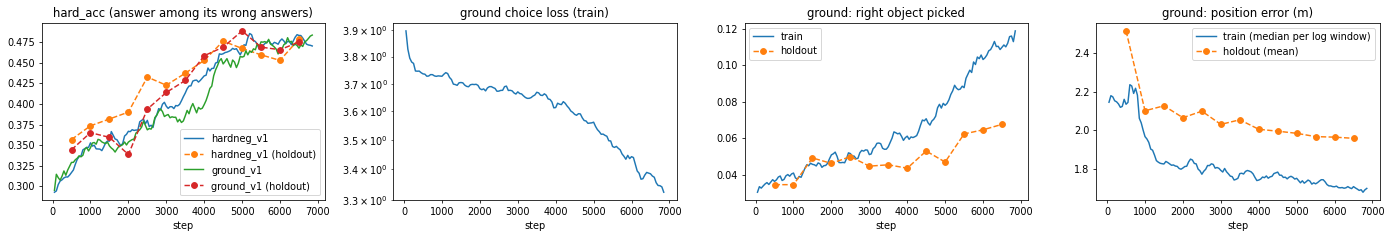

val_hard_acc          0.476
val_ground_acc        0.068
val_ground_error_m    1.959
Name: 142, dtype: float64

In [5]:
read = lambda p: pd.DataFrame([json.loads(l) for l in open(p)])
logs = {"hardneg_v1": read("../../hardneg_v1/results/hardneg_log.jsonl"), "ground_v1": read("../results/hardneg_log.jsonl")}
fig, ax = plt.subplots(1, 4, figsize=(20, 3.5))
for name, n in logs.items():
    a = n.dropna(subset=["hard_acc"])
    ax[0].plot(a.step, a.hard_acc.rolling(5, min_periods=1).mean(), label=name)
    v = n.dropna(subset=["val_hard_acc"]) if "val_hard_acc" in n else n.iloc[:0]
    ax[0].plot(v.step, v.val_hard_acc, "o--", label=name + " (holdout)")
g = logs["ground_v1"]; a = g.dropna(subset=["ground_acc"]); v = g.dropna(subset=["val_ground_acc"])
ax[1].plot(a.step, a.ground_loss.rolling(5, min_periods=1).mean()); ax[1].set_yscale("log")
ax[2].plot(a.step, a.ground_acc.rolling(5, min_periods=1).mean(), label="train"); ax[2].plot(v.step, v.val_ground_acc, "o--", label="holdout")
ax[3].plot(a.step, a.ground_error_m.rolling(5, min_periods=1).mean(), label="train (median per log window)"); ax[3].plot(v.step, v.val_ground_error_m, "o--", label="holdout (mean)")
for x, title in zip(ax, ["hard_acc (answer among its wrong answers)", "ground choice loss (train)", "ground: right object picked", "ground: position error (m)"]):
    x.set_title(title); x.set_xlabel("step")
for i in (0, 2, 3): ax[i].legend()
plt.tight_layout(); plt.show()
g.filter(like="val_").dropna(how="all").iloc[-1][["val_hard_acc", "val_ground_acc", "val_ground_error_m"]].astype(float).round(3)

- 定位学得很慢,而且到结束时还在升:训练集选对物体 3%(第 50 步)→ 4.3%(1450)→ 6.5%(3550)→ 11%(6350),选择损失 3.9 → 3.4;后三分之一升得最快,此时学习率已经在余弦下降的尾段。
- 位置误差在前 3,000 步从 2.15 m 降到约 1.77 m,之后基本不动(结束时 1.71 m)。
- 留出集:选对 3.5% → 6.8%,平均误差 2.5 m → 1.96 m(这里记的是平均值,第 3.3 节的 1.77 m 是中位数)。训练集和留出集有差距(11% 对 7%),但训练集本身就没学会,主要问题不是过拟合。
- 答案这边的 hard_acc 和 hardneg_v1 走势相同:加上定位损失没有拖慢答案损失,也没有帮到它。

## 3 结果

### 3.1 VSI-Bench

选择题准确率,官方的任务排法(相对方向取 easy / medium / hard 三档平均)。两个模型都没有数值头,答不了 4 个数值任务。

**覆盖范围**:模型需要相机位姿,只评了 ScanNet 和 ScanNet++ 的题(test 选择题 1,845 道)。ARKitScenes 的题没有位姿,没有评。这些数字不能直接和论文里的全集分数比。

In [6]:
MC = {"相对距离": ["object_rel_distance"], "相对方向": ["object_rel_direction_easy", "object_rel_direction_medium", "object_rel_direction_hard"],
      "路线规划": ["route_planning"], "出现顺序": ["obj_appearance_order"]}

def vsibench(runs, split, mode):
    table = {}
    for name, r in runs.items():
        mc = r[mode][f"vsibench_{split}_posed_f8"]
        col = {task: sum(100 * mc["type/" + k] for k in keys) / len(keys) for task, keys in MC.items()}
        col["选择题 4 任务平均"] = sum(col.values()) / 4
        col["全部题的准确率"] = 100 * mc["all"]
        table[name] = col
    return pd.DataFrame(table).round(1)

for split in ("test", "debiased"):
    for mode, label in (("real", "真场景"), ("shuffled", "换成另一题的场景"), ("zero", "全零场景 token")):
        print(f"VSI-Bench {split},{label}"); display(vsibench(RUNS, split, mode))
print("VSI-Bench test 各题型"); display(by_type(RUNS, "vsibench_test_posed_f8"))
print("VSI-Bench test,去词汇化(物体名换成 object A / B / ...)"); display(vsibench(DELEX, "test", "real"))

VSI-Bench test,真场景


,hardneg_v1,ground_v1
相对距离,26.2,25.4
相对方向,35.9,34.3
路线规划,33.3,16.7
出现顺序,40.9,42.1
选择题 4 任务平均,34.1,29.6
全部题的准确率,33.7,32.7


VSI-Bench test,换成另一题的场景


,hardneg_v1,ground_v1
相对距离,24.9,24.7
相对方向,36.6,32.8
路线规划,31.1,28.9
出现顺序,40.1,40.3
选择题 4 任务平均,33.2,31.7
全部题的准确率,33.2,31.9


VSI-Bench test,全零场景 token


,hardneg_v1,ground_v1
相对距离,22.5,27.8
相对方向,32.1,44.2
路线规划,32.2,20.0
出现顺序,29.9,37.4
选择题 4 任务平均,29.2,32.3
全部题的准确率,27.4,35.6


... (6 outputs left out)

VSI-Bench test 各题型


,hardneg_v1 real,hardneg_v1 real-shuffled,ground_v1 real,ground_v1 real-shuffled
all,33.7,0.4,32.7,0.9
obj_appearance_order,40.9,0.8,42.1,1.8
object_rel_direction_easy,50.8,0.8,46.7,-0.8
object_rel_direction_hard,27.3,-0.4,16.5,2.6
object_rel_direction_medium,29.6,-2.5,39.9,2.9
object_rel_distance,26.2,1.3,25.4,0.7
route_planning,33.3,2.2,16.7,-12.2


VSI-Bench test,去词汇化(物体名换成 object A / B / ...)


,hardneg_v1,ground_v1
相对距离,23.6,23.9
相对方向,45.1,33.1
路线规划,31.1,15.6
出现顺序,25.2,26.7
选择题 4 任务平均,31.3,24.8
全部题的准确率,31.2,26.4


- **没有变好**:test 选择题 4 任务平均 34.1 → 29.6,全部题的准确率 33.7 → 32.7;debiased 35.0 → 32.6。
- **两个模型的分数都与场景无关**:ground_v1 换场景 31.7、全零 32.3,都不低于真场景的 29.6。
- 4 任务平均的下降主要来自路线规划(33.3 → 16.7,只有 90 题,换场景后是 28.9)和方向题在档位之间的移动(hard 27.3 → 16.5,medium 29.6 → 39.9)。四选一掉到 16 说明模型固定偏向某个错误选项;这是选项偏向的移动,不是空间能力的变化。
- 去词汇化后 31.2 / 26.4,同样与场景无关。

### 3.2 留出集(答题)

训练时没见过的场景,6,786 题。长答案:正确答案句子对同一道题的错误答案句子。

In [7]:
print("长答案(随机 29.9)"); display(by_mode(RUNS, "holdout", "long/all"))
print("短答案"); display(by_mode(RUNS, "holdout", "short/all"))
print("长答案各题型"); display(by_type(RUNS, "holdout", lambda k: k.startswith("long/") and k != "long/all"))
print("去词汇化,长答案(随机 29.9)"); display(by_mode(DELEX, "holdout", "long/all"))
print("去词汇化,长答案各题型"); display(by_type(DELEX, "holdout", lambda k: k.startswith("long/") and k != "long/all"))

长答案(随机 29.9)


,real,shuffled,zero
hardneg_v1,46.7,44.1,42.8
ground_v1,46.8,43.4,43.2


短答案


,real,shuffled,zero
hardneg_v1,41.9,40.8,40.3
ground_v1,38.6,37.2,38.1


长答案各题型


,题数,随机,hardneg_v1 real,hardneg_v1 real-shuffled,ground_v1 real,ground_v1 real-shuffled
spar/appearance_order,1000.0,25.0,37.7,8.9,41.1,10.1
spar/spatial_imagination_oc_video_hard,1000.0,31.2,44.8,1.1,44.3,0.9
spar/spatial_imagination_oo_video_hard,1000.0,13.3,23.6,0.3,23.4,-0.8
vsi590k/appearance_order,632.0,25.0,45.7,4.9,44.0,12.0
vsi590k/relative_count,154.0,33.3,55.2,9.7,48.7,4.5
vsi590k/relative_direction_object,1000.0,37.3,46.1,0.3,48.2,0.4
vsi590k/relative_distance_object,1000.0,25.0,42.5,1.1,40.6,2.6
vsi590k/relative_size_object,1000.0,50.0,84.7,1.1,84.4,1.5


去词汇化,长答案(随机 29.9)


,real,shuffled,zero
hardneg_v1,31.8,32.8,32.2
ground_v1,33.0,32.9,32.9


去词汇化,长答案各题型


,题数,随机,hardneg_v1 real,hardneg_v1 real-shuffled,ground_v1 real,ground_v1 real-shuffled
spar/appearance_order,1000.0,25.0,23.4,-2.1,24.2,-0.8
spar/spatial_imagination_oc_video_hard,1000.0,31.2,33.5,0.2,36.8,1.5
spar/spatial_imagination_oo_video_hard,1000.0,13.3,13.5,-1.5,15.8,0.1
vsi590k/appearance_order,632.0,25.0,25.5,-2.1,28.2,2.8
vsi590k/relative_count,154.0,33.3,28.6,0.6,37.7,-4.5
vsi590k/relative_direction_object,1000.0,37.3,47.9,0.2,45.5,-1.9
vsi590k/relative_distance_object,1000.0,25.0,25.6,-2.4,23.8,-3.1
vsi590k/relative_size_object,1000.0,50.0,51.2,-0.5,54.2,3.9


- 长答案 46.8(hardneg_v1 46.7);真场景减换场景 +3.4(+2.6)。差值只在出现顺序题上明显(SPAR +10.1,VSI +12.0),这类题不需要定位;方向、距离、spatial_imagination 仍在 ±3 以内。
- 短答案 41.9 → 38.6。
- 去词汇化后 33.0(hardneg_v1 31.8,随机 29.9),真场景和换场景相同(+0.1)。事先定的线是离开 30 且真场景减换场景 ≥ 5,没有达到。

### 3.3 定位本身

留出集里有真值的 9,769 个名字。三种输入:real 真场景;shuffled 换成同批另一题的场景 token;zero 全零。"选对物体"是在本场景的候选中心里选中正确的那个。

留出集,带名字


,名字数,"误差中位数 m,real","误差中位数 m,shuffled","误差中位数 m,zero","选对物体 %,real","选对物体 %,shuffled","选对物体 %,zero","选对物体 %,随机"
all,9769.0,1.77,2.46,4.44,7.48,5.27,4.44,2.87
spar/appearance_order,1674.0,1.67,2.16,3.91,9.86,6.93,5.38,3.54
spar/spatial_imagination_oc_video_hard,1704.0,1.72,2.50,4.40,8.16,5.58,5.05,2.98
spar/spatial_imagination_oo_video_hard,2274.0,1.73,2.42,4.54,5.89,4.93,3.74,2.57
subset:scannet,5735.0,1.79,2.27,3.90,9.15,6.64,5.51,3.76
subset:scannetpp,4034.0,1.75,2.80,5.15,5.11,3.32,2.93,1.60
vsi590k/appearance_order,691.0,1.97,2.88,5.27,5.64,2.46,2.32,1.79
vsi590k/relative_count,3.0,6.17,13.05,23.25,0.00,0.00,0.00,1.56
vsi590k/relative_direction_object,1331.0,1.77,2.48,4.40,7.51,6.01,4.28,3.09
vsi590k/relative_distance_object,1506.0,1.95,2.71,4.70,6.97,4.71,4.85,2.51


留出集,去词汇化


,名字数,"误差中位数 m,real","误差中位数 m,shuffled","误差中位数 m,zero","选对物体 %,real","选对物体 %,shuffled","选对物体 %,zero","选对物体 %,随机"
all,9769.0,1.79,2.42,4.33,5.15,3.98,3.93,2.87
spar/appearance_order,1674.0,1.68,2.13,3.79,6.81,5.14,4.36,3.54
spar/spatial_imagination_oc_video_hard,1704.0,1.75,2.45,4.34,5.46,3.70,4.28,2.98
spar/spatial_imagination_oo_video_hard,2274.0,1.76,2.39,4.44,3.83,3.21,3.78,2.57
subset:scannet,5735.0,1.82,2.25,3.78,6.22,4.93,4.60,3.76
subset:scannetpp,4034.0,1.75,2.73,5.01,3.62,2.63,2.97,1.60
vsi590k/appearance_order,691.0,1.94,2.73,5.12,3.76,2.03,2.89,1.79
vsi590k/relative_count,3.0,6.44,13.29,23.29,0.00,0.00,0.00,1.56
vsi590k/relative_direction_object,1331.0,1.78,2.44,4.30,5.71,5.56,3.53,3.09
vsi590k/relative_distance_object,1506.0,1.96,2.65,4.50,4.98,3.52,4.38,2.51


参照:总是回答留出集的平均位置,误差中位数 2.06 m


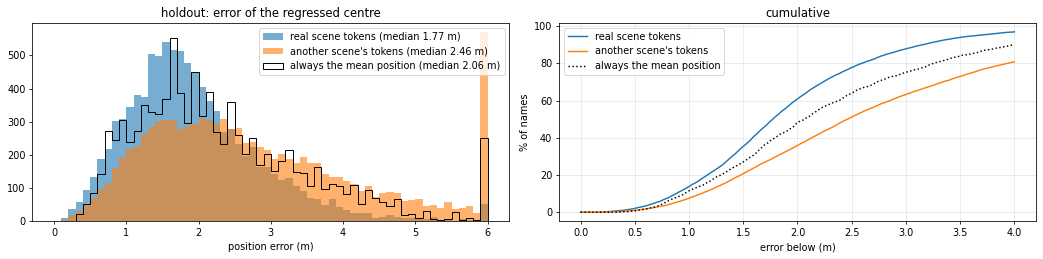

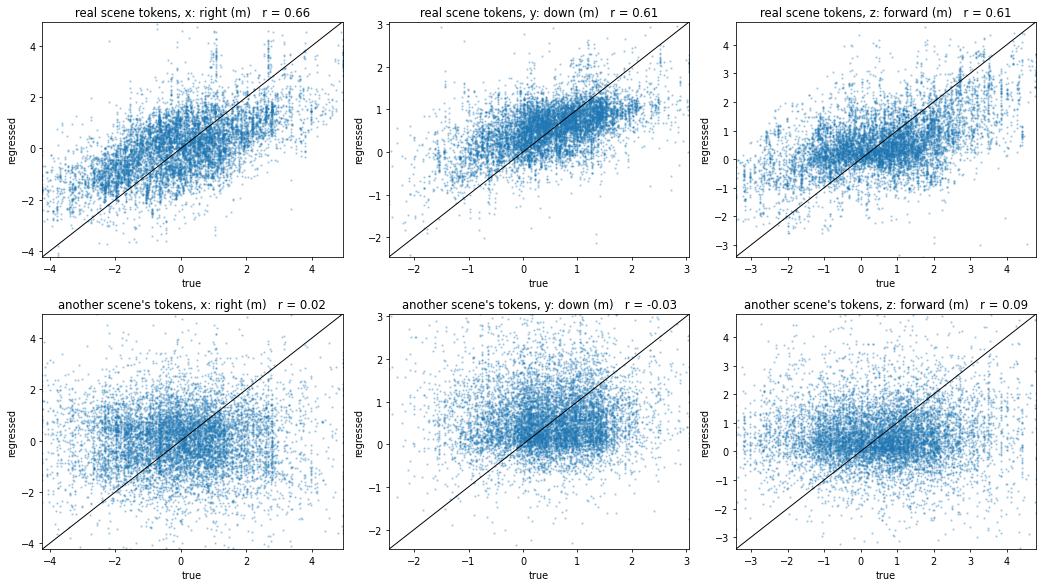

,真场景,换场景
x,0.663,0.016
y,0.607,-0.031
z,0.609,0.087


In [8]:
def ground_table(run):
    rows = {}
    for group, v in run["real"]["ground"].items():
        row = {"名字数": v["names"]}
        for m in MODES:
            row[f"误差中位数 m,{m}"] = run[m]["ground"][group]["error_m"]
        for m in MODES:
            row[f"选对物体 %,{m}"] = 100 * run[m]["ground"][group]["acc"]
        row["选对物体 %,随机"] = 100 * v["chance"]
        rows[group] = row
    return pd.DataFrame(rows).T.round(2)

print("留出集,带名字"); display(ground_table(G))
print("留出集,去词汇化"); display(ground_table(GD))
P = load("../results/figs/predictions.json")
real, shuf = pd.DataFrame(P["real"]), pd.DataFrame(P["shuffled"])
for d in (real, shuf):
    d[["tx", "ty", "tz"]] = np.array(d["true"].tolist()); d[["px", "py", "pz"]] = np.array(d["pred"].tolist())
    d["error"] = np.linalg.norm(d[["tx", "ty", "tz"]].values - d[["px", "py", "pz"]].values, axis=1)
mean = real[["tx", "ty", "tz"]].mean().values
const = np.linalg.norm(real[["tx", "ty", "tz"]].values - mean, axis=1)
print("参照:总是回答留出集的平均位置,误差中位数 %.2f m" % np.median(const))
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
bins = np.linspace(0, 6, 61)
ax[0].hist(real.error.clip(0, 6), bins, alpha=0.6, label="real scene tokens (median %.2f m)" % real.error.median())
ax[0].hist(shuf.error.clip(0, 6), bins, alpha=0.6, label="another scene's tokens (median %.2f m)" % shuf.error.median())
ax[0].hist(const.clip(0, 6), bins, histtype="step", color="black", label="always the mean position (median %.2f m)" % np.median(const))
ax[0].set_xlabel("position error (m)"); ax[0].set_title("holdout: error of the regressed centre"); ax[0].legend()
xs = np.linspace(0, 4, 200)
for d, label in ((real, "real scene tokens"), (shuf, "another scene's tokens")):
    ax[1].plot(xs, [(d.error < x).mean() * 100 for x in xs], label=label)
ax[1].plot(xs, [(const < x).mean() * 100 for x in xs], color="black", ls=":", label="always the mean position")
ax[1].set_xlabel("error below (m)"); ax[1].set_ylabel("% of names"); ax[1].set_title("cumulative"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))
for i, (d, label) in enumerate(((real, "real scene tokens"), (shuf, "another scene's tokens"))):
    for j, (axis, word) in enumerate(zip("xyz", ("x: right", "y: down", "z: forward"))):
        a = ax[i, j]; lo, hi = np.percentile(d["t" + axis], [1, 99])
        a.scatter(d["t" + axis], d["p" + axis], s=2, alpha=0.25)
        a.plot([lo, hi], [lo, hi], color="black", lw=1); a.set_xlim(lo, hi); a.set_ylim(lo, hi)
        r = np.corrcoef(d["t" + axis], d["p" + axis])[0, 1]
        a.set_title(f"{label}, {word} (m)   r = {r:.2f}"); a.set_xlabel("true"); a.set_ylabel("regressed")
plt.tight_layout(); plt.show()
pd.DataFrame({label: {"x": np.corrcoef(d.tx, d.px)[0, 1], "y": np.corrcoef(d.ty, d.py)[0, 1], "z": np.corrcoef(d.tz, d.pz)[0, 1]}
              for label, d in (("真场景", real), ("换场景", shuf))}).round(3)

- **误差 1.77 m,换场景 2.46 m,总答平均位置 2.06 m**。比不看场景好 0.3–0.7 m,离可用差得远:冻结 token 上的点提示探针是 0.27 m,类别探针是 0.95 m。
- **选对物体 7.5%**(换场景 5.3%,随机 2.9%)。
- **读到的是场景,不是名字**:回归坐标与真值的相关系数 0.66 / 0.61 / 0.61(x / y / z),换场景后约 0,说明输出确实来自场景 token;但把名字换成 object A / B 之后误差仍是 1.79 m,选对比例从 7.5% 掉到 5.1%。也就是说,位置信息的大部分与"问的是哪个物体"无关,更像是"这个场景里的物体大致分布在哪"。
- 回归输出的散布比真值小(标准差 1.3 / 0.6 / 1.2 m 对 1.9 / 1.0 / 1.8 m):不确定时往中间靠。
- ScanNet 和 ScanNet++ 上的误差相同(1.79 / 1.75 m),两种来源的真值表现一致。

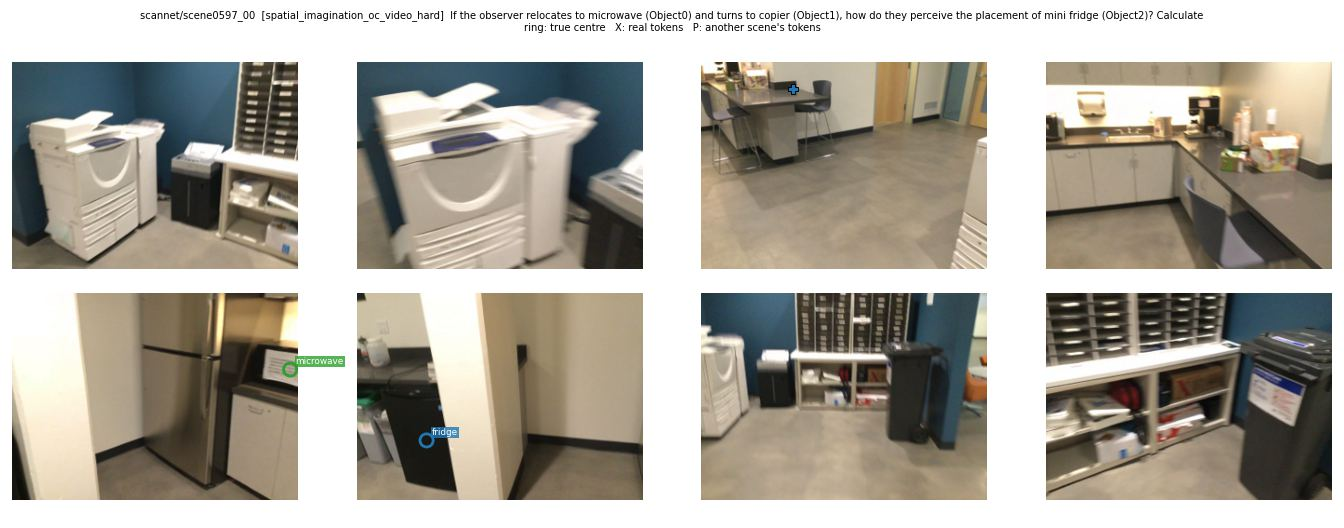

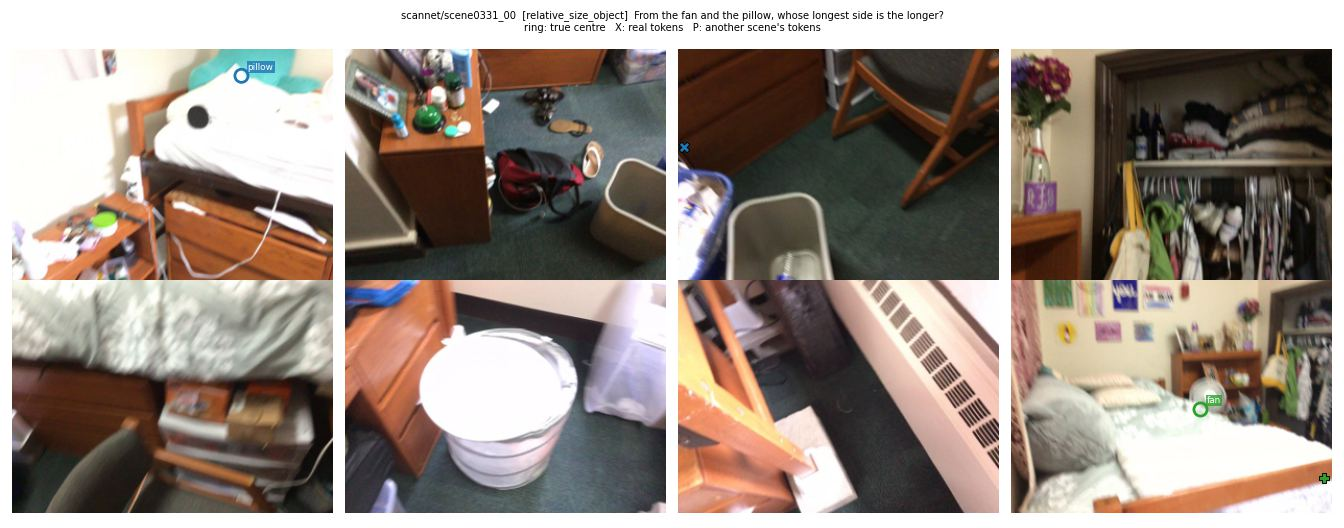

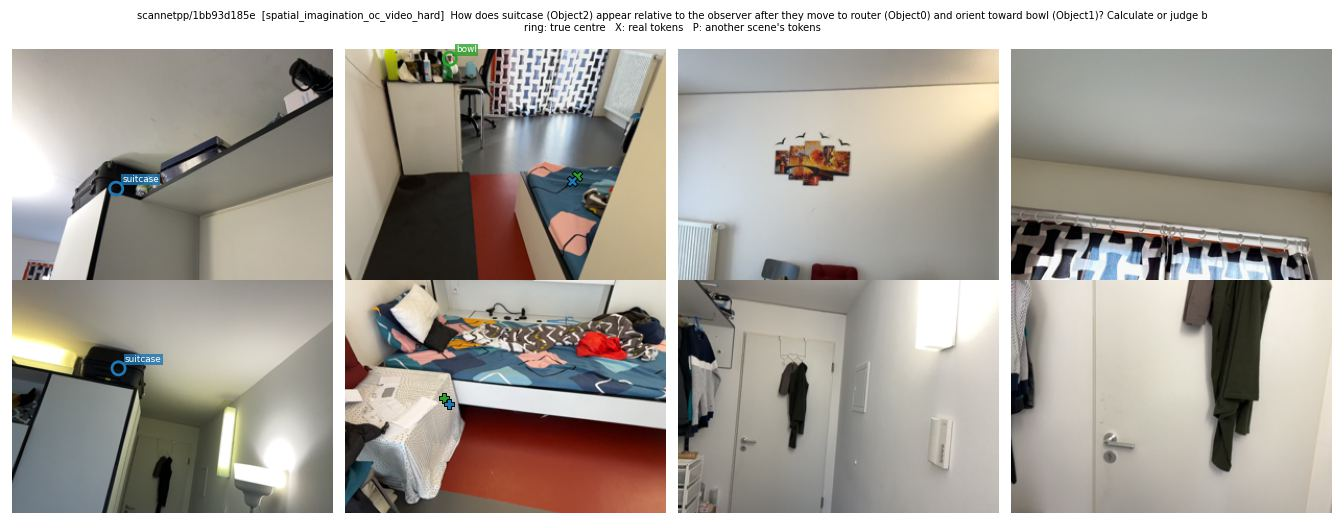

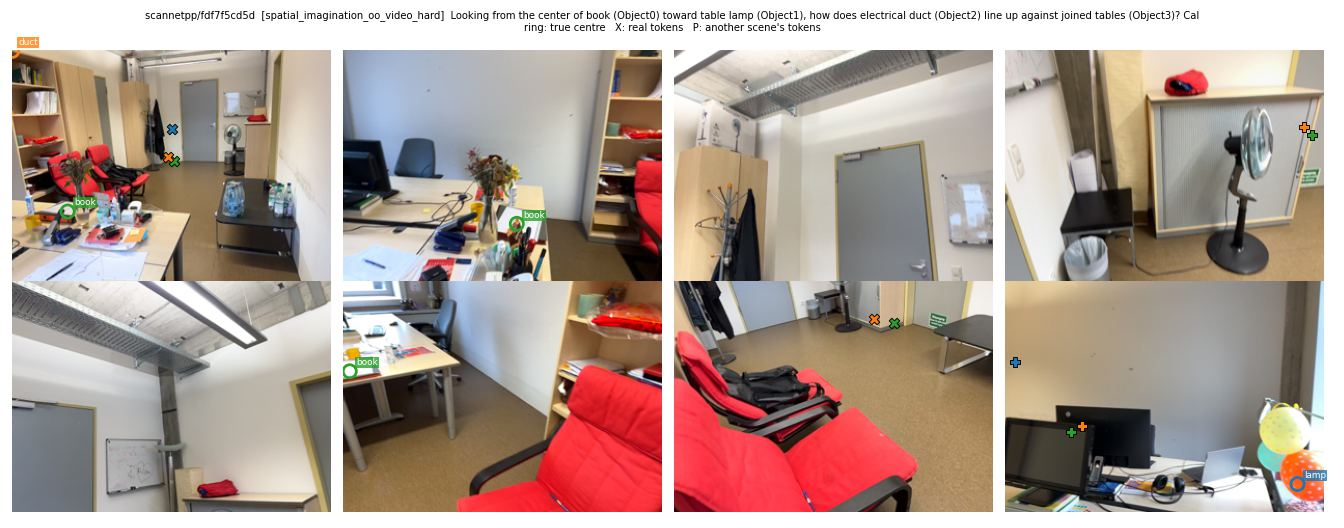

In [9]:
for name in ("pred_scannet_1", "pred_scannet_0", "pred_scannetpp_0", "pred_scannetpp_1"):
    picture(f"../results/figs/{name}.png")

圆圈是真值;X 是模型用真场景 token 回归出的中心,P 是换成另一场景 token 时的输出(落在所有视角之外的不画)。多数预测不在物体上,不少落在视野之外。

## 4 结论与下一步

1. **数据这一步是成的**:71.5 万个名字有了可核对的 3D 位置,覆盖 ScanNet 和 ScanNet++,今后任何 grounding 方案都可以直接用 `experiments/ground_v1/data/`。
2. **在第 4 层的名字 token 上直接加位置监督,一个 epoch 内没有学会"名字 → 物体"**。模型主要学到了与名字无关的场景布局,答题和 VSI-Bench 都没有受益。
3. **瓶颈的性质变清楚了一点**:训练集上也只选对 11–13%,所以主要不是过拟合,而类别探针是过拟合。带框场景太少解释不了这次的结果。
4. **训练没有收敛**:选对比例到结束时还在升,而且越到后面越快。这次的结果不能说明这个结构学不会,只能说明一个 epoch 不够。

**我的解读(没有验证)**:

- 3DRAE 的 1024 个场景 token 是全场景共享的潜变量,没有空间局部性。名字 token 没有"哪几个 token 是这个物体"可以去对,只能读出整体布局。点提示探针之所以能到 0.27 m,是因为查询里带着射线,等于告诉了它往哪看。
- 训练只有 1,717 次参数更新,定位损失和答案损失同时训练,曲线还在升;训更久、或只训定位能到多少没有测。

**可选的下一步(未定)**:

- **先做这个**:延长训练(2–3 个 epoch,或只训定位),看选对比例和误差能到哪。能明显低于 1 m,就是训练量的问题;停在 1.7 m 附近,就是场景 token 的问题。
- 给 predictor 一份可以按位置寻址的输入:在 3DRAE token 旁边加带射线的 DINOv2 patch token,或每个物体名配一个带射线的查询(slots_v2 的做法,但改用这批真值而不是 dino.txt 的候选)。
- 之前提过的上界检查:把真值中心直接作为点提示喂给 predictor,看去词汇化的留出集能否离开 30。它回答的是"找到了物体之后,模型会不会用"。